# Air Quality Index — Tree-based Regression

Small AQI regression on the UCI Air Quality dataset (hourly sensor readings in an Italian city for ~1 year). Target is the CO concentration (a proxy AQI signal). Sensors have known broken stretches encoded as -200; those rows have to be dropped.

I tried to make the loader resilient to missing internet — if the UCI ZIP isn't already in `../../data/air_quality/`, I synthesize a small stand-in.

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

DATA = Path('../../data/air_quality'); DATA.mkdir(parents=True, exist_ok=True)
CSV = DATA / 'AirQualityUCI.csv'

In [2]:
if CSV.exists():
    # UCI's CSV uses ; as separator and , as decimal
    df = pd.read_csv(CSV, sep=';', decimal=',')
    df = df.dropna(how='all').dropna(axis=1, how='all')
    print('loaded real UCI file', df.shape)
else:
    # Synthetic fallback. Hourly readings over 6 months, broken sensor periods marked -200.
    rng = np.random.default_rng(5)
    N = 24 * 180
    hour = np.tile(np.arange(24), N // 24 + 1)[:N]
    co = 1.5 + 0.6 * np.sin(2 * np.pi * hour / 24) + rng.normal(0, 0.3, N)
    co = np.clip(co, 0.1, None)
    no2 = 50 + 25 * np.sin(2 * np.pi * hour / 24 + 0.4) + rng.normal(0, 8, N)
    temp = 18 + 8 * np.sin(2 * np.pi * np.arange(N) / (24 * 30)) + rng.normal(0, 2, N)
    rh = 50 + 15 * np.sin(2 * np.pi * np.arange(N) / (24 * 7)) + rng.normal(0, 6, N)
    df = pd.DataFrame({'CO(GT)': co, 'NO2(GT)': no2, 'T': temp, 'RH': rh, 'hour': hour})
    # inject a fake broken-sensor run
    df.loc[1000:1100, 'NO2(GT)'] = -200
    print('synthesized', df.shape)

synthesized (4320, 5)


In [3]:
# -200 is UCI's missing-data sentinel. Treat as NaN, then drop rows where the target is gone.
df = df.replace(-200, np.nan)
df = df.dropna(subset=['CO(GT)']).copy()
if 'hour' not in df.columns:
    if 'Time' in df.columns:
        df['hour'] = df['Time'].astype(str).str.slice(0, 2).astype(int, errors='ignore')
    else:
        df['hour'] = 12
print('rows after cleaning', df.shape)

rows after cleaning (4320, 5)


## EDA

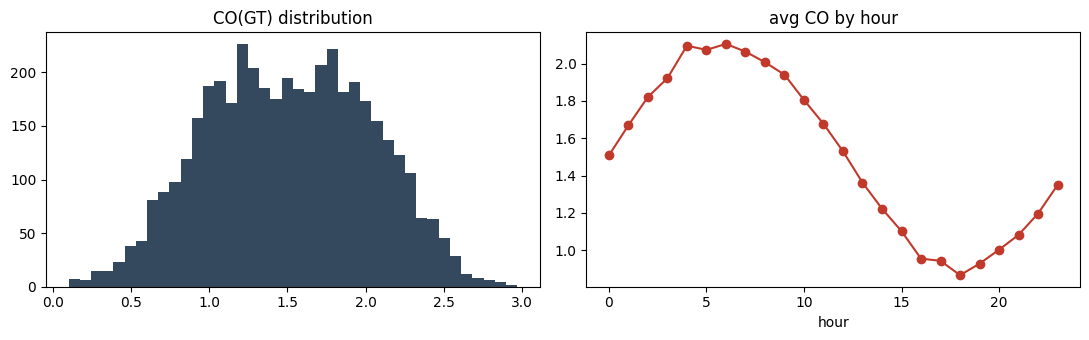

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df['CO(GT)'], bins=40, color='#34495e'); ax[0].set_title('CO(GT) distribution')
df.groupby('hour')['CO(GT)'].mean().plot(ax=ax[1], marker='o', color='#c0392b')
ax[1].set_title('avg CO by hour'); plt.tight_layout(); plt.show()

In [5]:
FEATURES = [c for c in df.columns if c not in ['CO(GT)', 'Date', 'Time']]
FEATURES = [c for c in FEATURES if np.issubdtype(df[c].dtype, np.number)]
X = df[FEATURES].fillna(df[FEATURES].median()).values
y = df['CO(GT)'].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
print(f'MAE  = {mean_absolute_error(y_te, pred):.3f}')
print(f'R^2  = {r2_score(y_te, pred):.3f}')

MAE  = 0.250
R^2  = 0.646


In [6]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
imp

hour       0.883328
NO2(GT)    0.043134
RH         0.039985
T          0.033553
dtype: float64

## Wrap-up

Tree model on the cleaned UCI features does fine. If I were taking this further I'd:
- Treat the time-series structure properly (random split leaks neighbouring hours; a block split by day or week is more honest).
- Replace median-imputation on the broken-sensor stretches with a forward-fill or a small interpolation. Median imputation flattens the daily pattern.
- See whether a small neural network can match this — that's project 85.